# 05 · Centrage et réduction des images, découpage train / test

**Plan (Mathis, 13 novembre)**
- On découpe la saison en blocs de trois semaines : **deux semaines d'entraînement, puis une semaine de test**, en alternance.
- Le découpage porte sur **toutes les photos** du catalogue, pas seulement celles déjà annotées : chaque photo est étiquetée `train` ou `test` selon sa semaine.
- Prétraitement : on **centre** l'image (on enlève à chaque canal R, V, B sa moyenne sur l'image), avec une option noir et blanc, puis on peut la **réduire** (diviser par l'écart type).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMAGES = ROOT / "data" / "images"
CATALOGUE = ROOT / "data_treatment" / "catalogue_images.csv"

## 1. Les deux fonctions

- `centrer(img, noir_et_blanc=False)` : renvoie l'image (tableau `float`) dont chaque canal est de moyenne nulle. Avec `noir_et_blanc=True`, l'image est d'abord passée en niveaux de gris (un seul canal).
- `reduire(img)` : divise chaque canal par son écart type. À appliquer sur une image centrée : le résultat a, pour chaque canal, une moyenne 0 et un écart type 1.

In [2]:
def centrer(img, noir_et_blanc=False):
    """Centre l'image : soustrait à chaque canal (R, V, B) sa moyenne sur l'image.

    img : image PIL, ou tableau numpy (H, W, 3) ou (H, W).
    noir_et_blanc : si True, convertit d'abord en niveaux de gris -> tableau (H, W).
    Renvoie un tableau float de moyenne nulle (par canal).
    """
    if isinstance(img, Image.Image):
        img = img.convert("L" if noir_et_blanc else "RGB")
    x = np.asarray(img, dtype=np.float64)
    if noir_et_blanc and x.ndim == 3:
        x = x[..., :3] @ np.array([0.299, 0.587, 0.114])   # luminance (même formule que PIL)
    moyenne = x.mean(axis=(0, 1))                            # une moyenne par canal (ou un nombre en N&B)
    return x - moyenne


def reduire(img):
    """Réduit l'image : divise chaque canal par son écart type sur l'image.

    img : tableau (H, W, 3) ou (H, W), en général déjà centré par centrer().
    Un canal constant (écart type nul) est laissé tel quel.
    """
    x = np.asarray(img, dtype=np.float64)
    ecart_type = x.std(axis=(0, 1))
    ecart_type = np.where(ecart_type == 0, 1.0, ecart_type)
    return x / ecart_type

Vérification sur une image : après `centrer`, moyenne nulle par canal ; après `reduire`, écart type 1.

In [3]:
img = Image.open(IMAGES / "2026-11-03-104512.jpg")       # image de référence du catalogue
c = centrer(img)
cr = reduire(c)
print("moyennes d'origine    :", np.asarray(img, float).mean(axis=(0, 1)).round(1))
print("moyennes centrée      :", c.mean(axis=(0, 1)).round(6))
print("écarts types centrée  :", c.std(axis=(0, 1)).round(1))
print("écarts types réduite  :", cr.std(axis=(0, 1)).round(6))
nb = reduire(centrer(img, noir_et_blanc=True))
print("noir et blanc         :", nb.shape, round(nb.mean(), 6), round(nb.std(), 6))

moyennes d'origine    : [153.3 157.6 155.2]
moyennes centrée      : [ 0. -0.  0.]
écarts types centrée  : [37.2 37.4 43.3]


écarts types réduite  : [1. 1. 1.]
noir et blanc         : (1753, 1919) 0.0 1.0


## 2. Avant / après sur quelques images

Une image centrée a des valeurs négatives : pour l'afficher, on ramène l'intervalle moyenne ± 3 écarts types sur [0, 1] (affichage seulement).

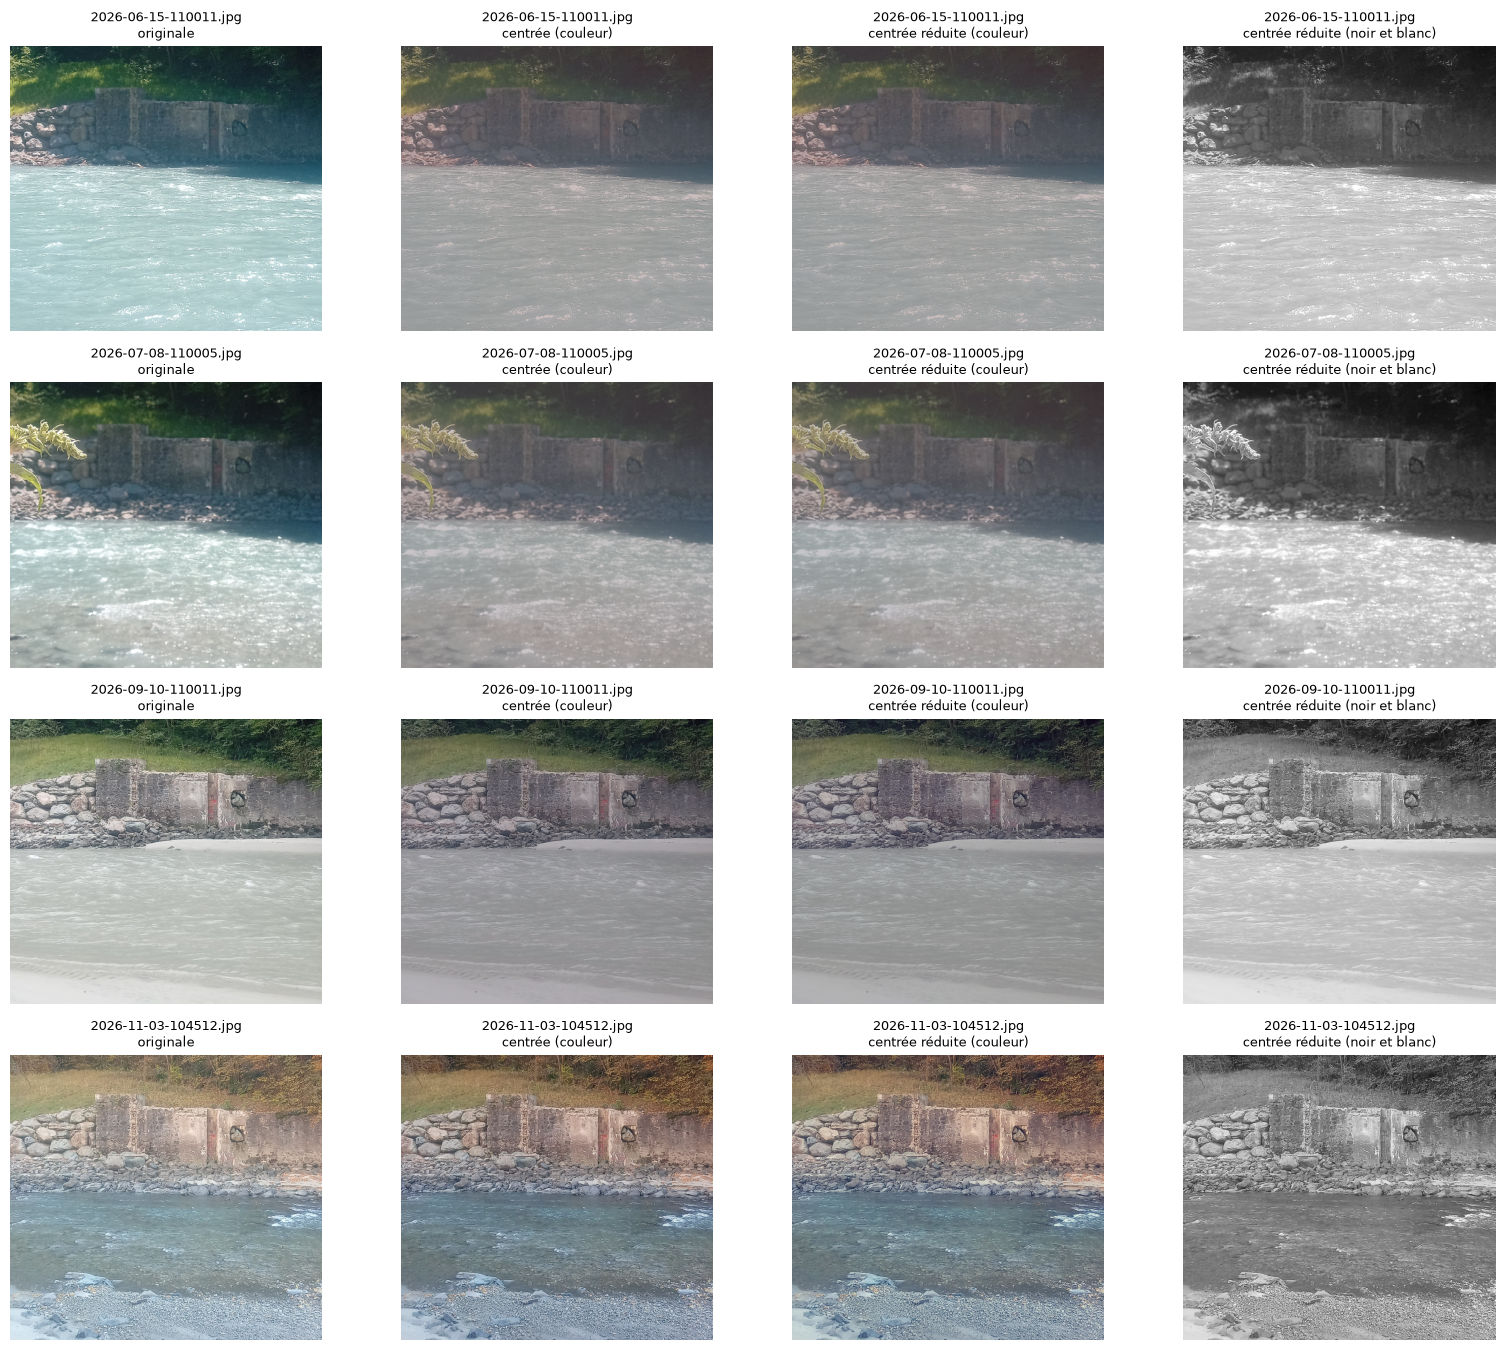

In [4]:
def pour_afficher(x):
    """Ramène un tableau centré/réduit dans [0, 1] pour imshow (moyenne ± 3 écarts types)."""
    m, s = x.mean(), x.std() or 1.0
    return np.clip((x - m) / (6 * s) + 0.5, 0, 1)

exemples = ["2026-06-15-101501.jpg", "2026-07-20-120001.jpg", "2026-09-10-151501.jpg", "2026-11-03-104512.jpg"]
exemples = [f if (IMAGES / f).exists() else None for f in exemples]
# si un nom n'existe pas, on prend l'image de jour la plus proche dans le dossier
tous = sorted(p.name for p in IMAGES.glob("*.jpg"))
def plus_proche(nom):
    return min(tous, key=lambda f: abs(pd.Timestamp(f[:10]) - pd.Timestamp(nom[:10])) + pd.Timedelta(hours=abs(int(f[11:13]) - 11)))
exemples = [e or plus_proche(n) for e, n in zip(exemples, ["2026-06-15-101501.jpg", "2026-07-20-120001.jpg", "2026-09-10-151501.jpg", "2026-11-03-104512.jpg"])]

fig, axes = plt.subplots(len(exemples), 4, figsize=(16, 3.4 * len(exemples)))
for ligne, nom in zip(axes, exemples):
    img = Image.open(IMAGES / nom)
    vues = [
        ("originale", np.asarray(img), None),
        ("centrée (couleur)", pour_afficher(centrer(img)), None),
        ("centrée réduite (couleur)", pour_afficher(reduire(centrer(img))), None),
        ("centrée réduite (noir et blanc)", pour_afficher(reduire(centrer(img, noir_et_blanc=True))), "gray"),
    ]
    for ax, (titre, x, cmap) in zip(ligne, vues):
        ax.imshow(x, cmap=cmap)
        ax.set_title(f"{nom}\n{titre}", fontsize=9)
        ax.axis("off")
plt.tight_layout()

## 3. Découpage train / test de toutes les photos

Semaine = semaine du calendrier (du lundi au dimanche), numérotée à partir de la première semaine de la saison.
Dans chaque bloc de trois semaines : semaines 0 et 1 → `train`, semaine 2 → `test`.
Le résultat est enregistré dans `data_treatment/split_train_test.csv` (`fichier, semaine, split`) : le catalogue n'est pas modifié.

In [5]:
cat = pd.read_csv(CATALOGUE, usecols=["fichier", "datetime", "exploitable", "niveau_px"])
date = pd.to_datetime(cat["fichier"].str[:10])
lundi = date - pd.to_timedelta(date.dt.day_of_week, unit="D")
cat["semaine"] = ((lundi - lundi.min()).dt.days // 7).astype(int)
cat["split"] = np.where(cat["semaine"] % 3 == 2, "test", "train")

cat[["fichier", "semaine", "split"]].to_csv(ROOT / "data_treatment" / "split_train_test.csv", index=False)

print("toutes les photos :", cat["split"].value_counts().to_dict())
print("photos exploitables :", cat.loc[cat["exploitable"] == "oui", "split"].value_counts().to_dict())
print("photos déjà annotées (niveau_px dans le catalogue) :", cat.loc[cat["niveau_px"].notna(), "split"].value_counts().to_dict())
cat.groupby("semaine").agg(debut=("fichier", lambda f: f.min()[:10]), photos=("fichier", "size"), split=("split", "first"))

toutes les photos : {'train': 3465, 'test': 2062}
photos exploitables : {'train': 2506, 'test': 1395}
photos déjà annotées (niveau_px dans le catalogue) : {'train': 13}


,debut,photos,split
semaine,,,
0,2026-05-29,22,train
1,2026-06-01,81,train
2,2026-06-11,141,test
3,2026-06-15,237,train
4,2026-06-22,152,train
5,2026-06-29,147,test
6,2026-07-06,138,train
12,2026-08-21,31,train
13,2026-08-28,18,train


In [6]:
# Annotations de tous les annotateurs (fichiers niveau_*.csv), réparties en train / test
ann = pd.concat([pd.read_csv(f).assign(annotateur=f.stem.removeprefix("niveau_"))
                 for f in sorted((ROOT / "data_treatment" / "annotations").glob("niveau_*.csv"))])
ann = ann.merge(cat[["fichier", "split"]], on="fichier", how="left")
pd.crosstab(ann["annotateur"], ann["split"], margins=True)

split,test,train,All
annotateur,,,
aymen,0,25,25
mathis,201,418,619
All,201,443,644


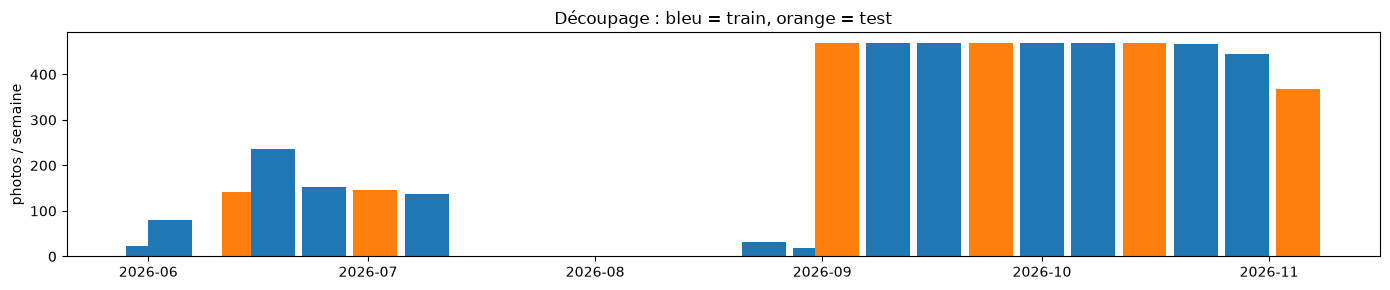

In [7]:
fig, ax = plt.subplots(figsize=(14, 3))
par_semaine = cat.groupby("semaine").agg(debut=("fichier", lambda f: pd.Timestamp(f.min()[:10])), photos=("fichier", "size"), split=("split", "first"))
ax.bar(par_semaine["debut"], par_semaine["photos"], width=6, align="edge",
       color=par_semaine["split"].map({"train": "tab:blue", "test": "tab:orange"}))
ax.set_ylabel("photos / semaine")
ax.set_title("Découpage : bleu = train, orange = test")
plt.tight_layout()

## 4. Produit scalaire d'images test avec toutes les images train

On prend **N_test = 20** photos test annotées au hasard. Chaque photo (test ou train) est passée en **noir et blanc, centrée puis réduite** : `reduire(centrer(img, noir_et_blanc=True))`. On la réduit d'abord à 1/4 (480 × 438 pixels) pour aller plus vite.

Pour une photo test $x$ et une photo train $r$, toutes deux centrées réduites, on calcule $\dfrac{1}{p}\langle x, r\rangle$ ($p$ = nombre de pixels). C'est le coefficient de corrélation entre les deux images : il vaut 1 si elles sont identiques et reste entre -1 et 1.

**Hauteur d'eau** : niveau annoté, corrigé du mouvement de la caméra, `niveau_px - decalage_y` (voir `define_water_lvl.py`). Plus ce nombre est **petit**, plus l'eau est **haute**.

Pour chaque photo test, un graphique : en abscisse les photos train **rangées par hauteur d'eau croissante** (de l'eau la plus basse à l'eau la plus haute), en ordonnée le produit scalaire avec la photo test. Le **trait rouge vertical** est placé là où viendrait la photo test dans ce classement, c'est-à-dire à sa hauteur d'eau. L'étoile marque la photo train la plus ressemblante (le maximum).


In [8]:
N_TEST = 20
ECHELLE = 4                     # images réduites à 1/4 avant le calcul
TAILLE = (1919 // ECHELLE, 1753 // ECHELLE)

annot = (ann.merge(pd.read_csv(CATALOGUE, usecols=["fichier", "decalage_y"]), on="fichier")
            .dropna(subset=["niveau_px"]).drop_duplicates("fichier"))
annot["hauteur_px"] = annot["niveau_px"] - annot["decalage_y"]      # niveau corrigé du mouvement de la caméra

# train : rangées par hauteur d'eau croissante = hauteur_px décroissante (y grand = eau basse)
train = annot[annot["split"] == "train"].sort_values("hauteur_px", ascending=False).reset_index(drop=True)
test = (annot[annot["split"] == "test"].sample(N_TEST, random_state=0)
            .sort_values("hauteur_px", ascending=False).reset_index(drop=True))
print(f"{len(train)} photos train, {N_TEST} photos test (sur {(annot['split'] == 'test').sum()} test annotées)")


def vecteur(nom):
    """Photo en noir et blanc, réduite à 1/ECHELLE, centrée réduite, mise à plat."""
    img = Image.open(IMAGES / nom)
    img.draft("L", TAILLE)                        # décodage JPEG directement à petite taille
    img = img.convert("L").resize(TAILLE)
    return reduire(centrer(img, noir_et_blanc=True)).ravel().astype(np.float32)


X_train = np.stack([vecteur(f) for f in train["fichier"]])
X_test = np.stack([vecteur(f) for f in test["fichier"]])
PS = X_test @ X_train.T / X_train.shape[1]       # (N_TEST, n_train) : produit scalaire / nb de pixels
print("matrice des produits scalaires :", PS.shape)

443 photos train, 20 photos test (sur 201 test annotées)


matrice des produits scalaires : (20, 443)


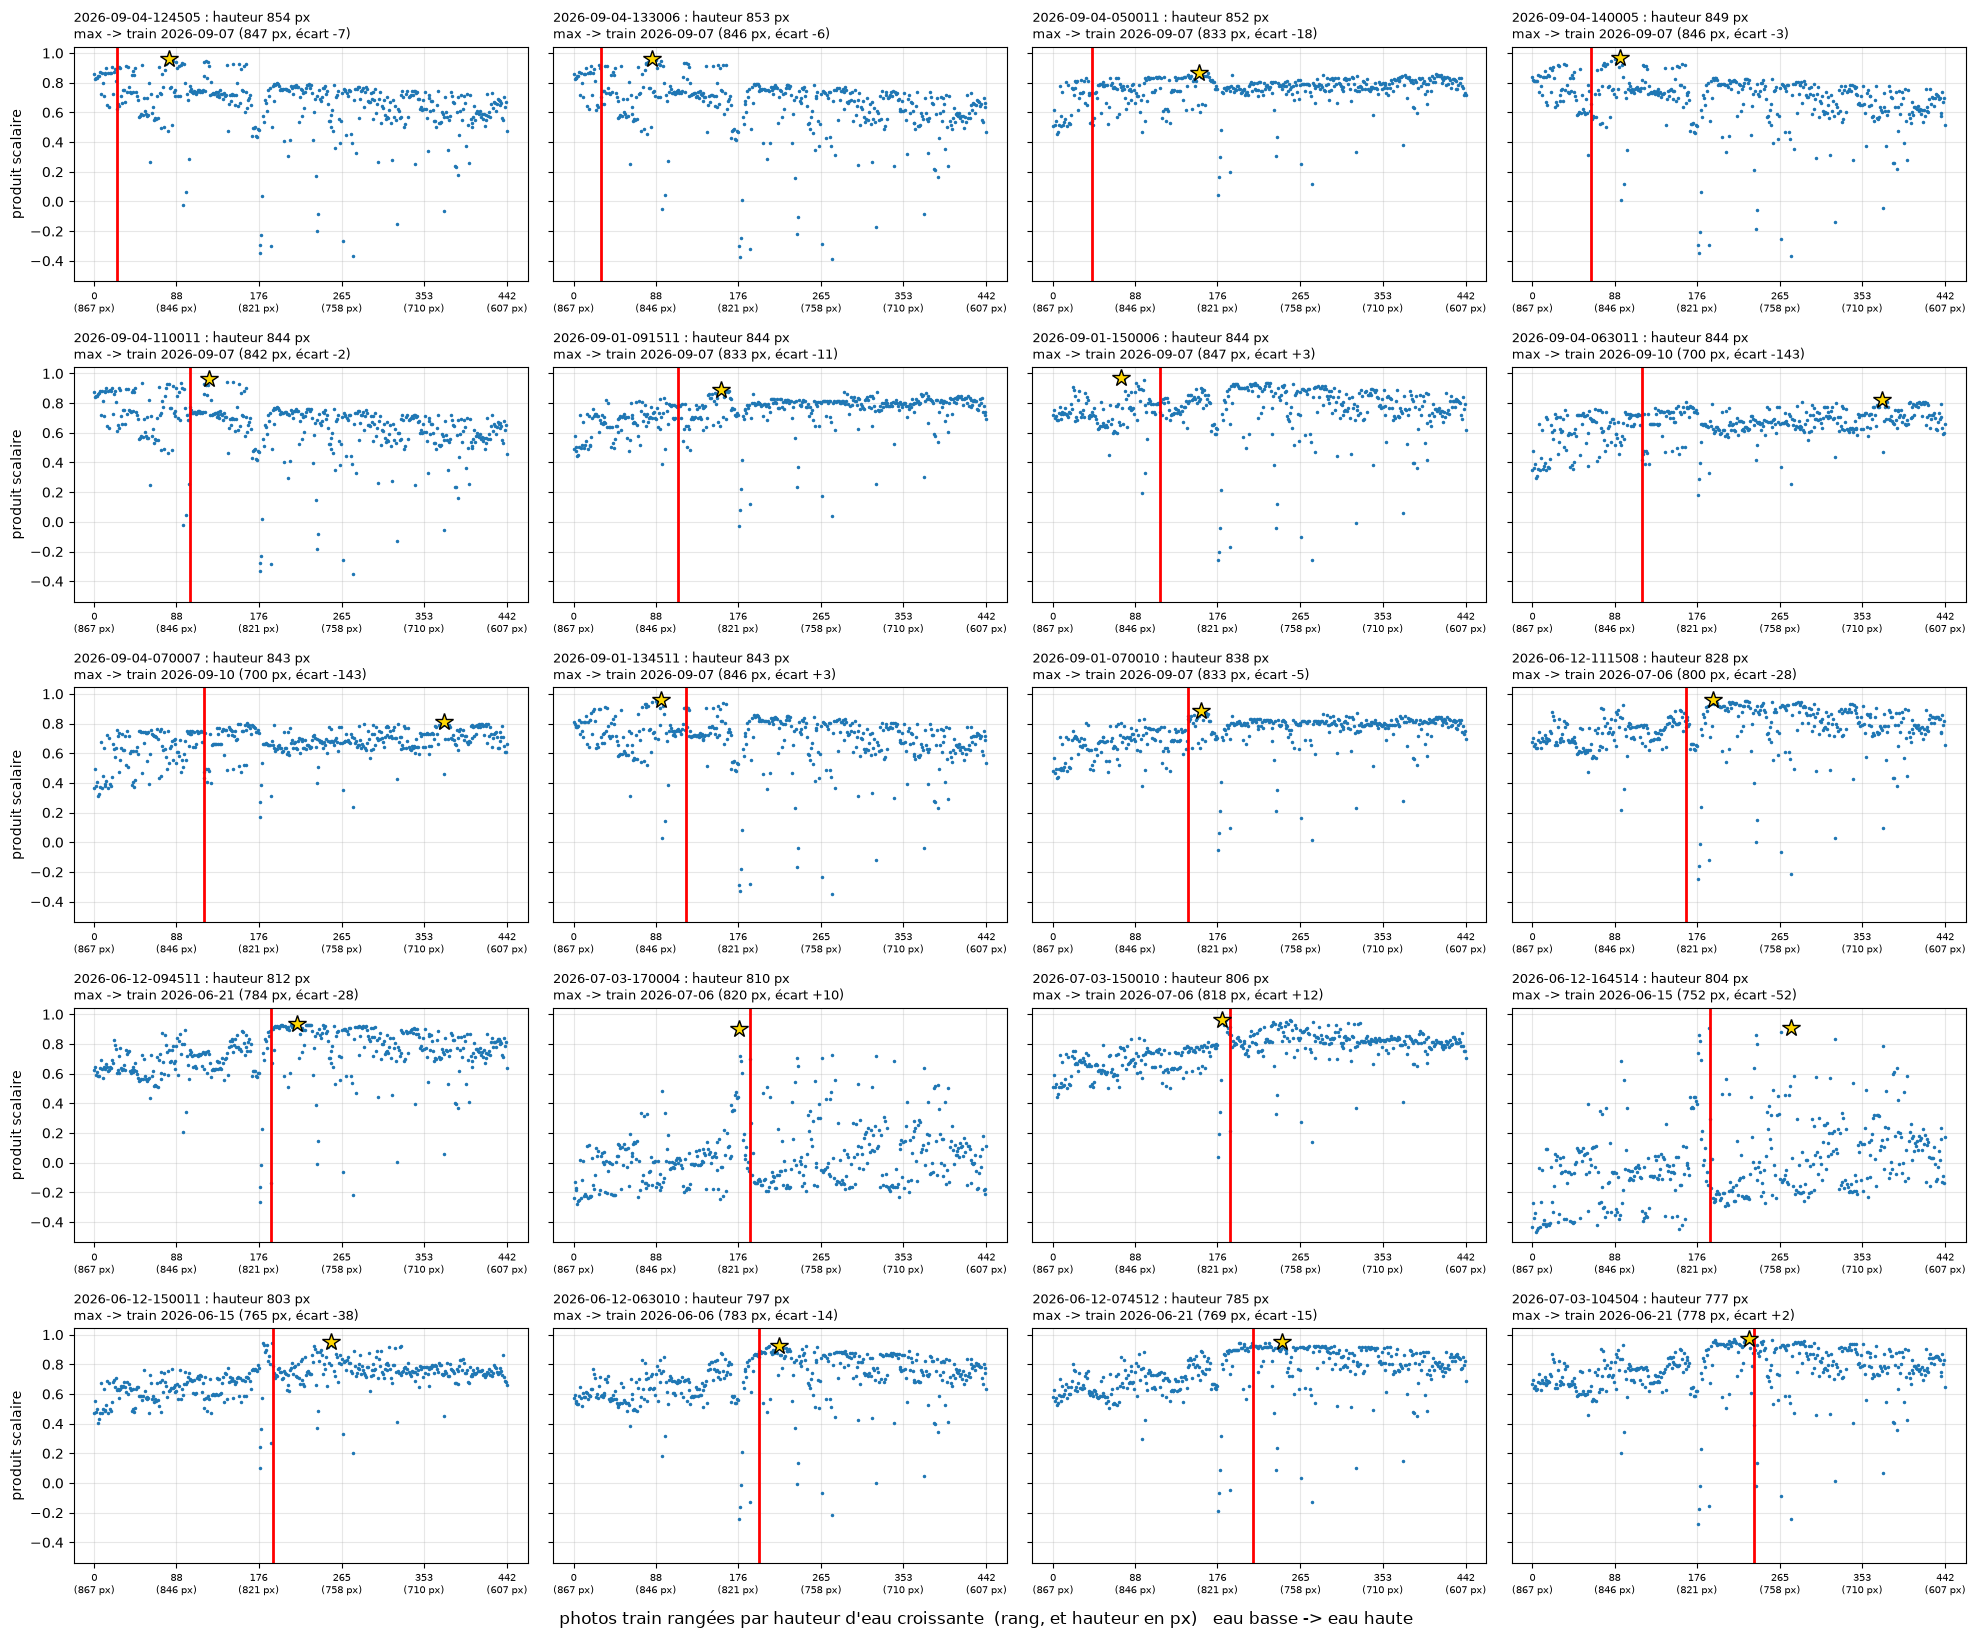

In [9]:
h_train = train["hauteur_px"].to_numpy()
rang = np.arange(len(train))
# graduations : rang en bas, hauteur correspondante (px) entre parenthèses
graduations = np.linspace(0, len(train) - 1, 6).astype(int)
etiquettes = [f"{r}\n({h_train[r]:.0f} px)" for r in graduations]

ncol = 4
fig, axes = plt.subplots(int(np.ceil(N_TEST / ncol)), ncol, figsize=(20, 3.3 * np.ceil(N_TEST / ncol)), sharey=True)
for i, (ax, t) in enumerate(zip(axes.ravel(), test.itertuples())):
    ax.plot(rang, PS[i], ".", ms=3)
    # position de la photo test dans le classement : nb de photos train d'eau plus basse
    pos = np.searchsorted(-h_train, -t.hauteur_px)
    ax.axvline(pos, color="red", lw=2)
    j = int(np.argmax(PS[i]))
    ax.plot(j, PS[i, j], "*", color="gold", mec="k", ms=13)
    ax.set_title(f"{t.fichier[:-4]} : hauteur {t.hauteur_px:.0f} px\n"
                 f"max -> train {train.at[j, 'fichier'][:10]} ({h_train[j]:.0f} px, écart {h_train[j] - t.hauteur_px:+.0f})",
                 fontsize=9, loc="left")
    ax.set_xticks(graduations, etiquettes, fontsize=7)
    ax.grid(alpha=.3)
for ax in axes.ravel()[N_TEST:]:
    ax.axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel("produit scalaire")
fig.supxlabel("photos train rangées par hauteur d'eau croissante  (rang, et hauteur en px)   eau basse -> eau haute")
plt.tight_layout()

In [10]:
# Résumé : hauteur de la photo train la plus ressemblante vs vraie hauteur
pred = h_train[PS.argmax(axis=1)]
ecart = pred - test["hauteur_px"].to_numpy()
print(f"écart (hauteur prédite - vraie) : médiane |écart| = {np.median(np.abs(ecart)):.1f} px, "
      f"max = {np.abs(ecart).max():.1f} px, {np.sum(np.abs(ecart) <= 10)}/{N_TEST} à 10 px près")

écart (hauteur prédite - vraie) : médiane |écart| = 11.6 px, max = 143.4 px, 8/20 à 10 px près


## 5. Pistes 1 et 2 : bande de la rivière et recalage

Sur l'image entière, le produit scalaire retrouve surtout la **date** (ciel, montagne, végétation, lumière) plutôt que le niveau d'eau. On essaie deux corrections :

- **Piste 1, bande de la rivière** : on ne garde que la bande y ∈ [500, 1200] où se trouve la frontière eau / berge, comme dans le notebook 04. On garde toute la largeur, avec une marge de 40 px de chaque côté pour la piste 2.
- **Piste 2, recalage** : la caméra bouge d'une photo à l'autre. `decalage_x` et `decalage_y` (dans le catalogue) donnent le déplacement de la scène par rapport à l'image de référence : un point situé en y sur la référence est en y + `decalage_y` sur la photo. On découpe donc la bande en la décalant d'autant, pour que chaque pixel corresponde au même endroit de la scène sur toutes les photos.

Ensuite, même traitement qu'avant : noir et blanc, réduction à 1/4, centrage, réduction, produit scalaire divisé par le nombre de pixels.

In [11]:
Y0, Y1, MARGE, W0 = 500, 1200, 40, 1919
decalages = pd.read_csv(CATALOGUE, usecols=["fichier", "decalage_x", "decalage_y"]).set_index("fichier")


def vecteur_bande(nom, recaler):
    """Bande y ∈ [Y0, Y1] (recalée ou non), noir et blanc, réduite à 1/ECHELLE, centrée réduite, mise à plat."""
    dx, dy = decalages.loc[nom, ["decalage_x", "decalage_y"]] if recaler else (0.0, 0.0)
    img = Image.open(IMAGES / nom)
    img.draft("L", (img.size[0] // 2, img.size[1] // 2))   # décodage à 1/2, plus rapide
    s = img.size[0] / W0                                     # facteur pleine résolution -> image décodée
    boite = [round(v * s) for v in (MARGE + dx, Y0 + dy, W0 - MARGE + dx, Y1 + dy)]
    taille = ((W0 - 2 * MARGE) // ECHELLE, (Y1 - Y0) // ECHELLE)
    img = img.convert("L").crop(boite).resize(taille)
    return reduire(centrer(img, noir_et_blanc=True)).ravel().astype(np.float32)


PS_variantes = {"image entière": PS}
for nom_var, recaler in [("bande", False), ("bande recalée", True)]:
    Xtr = np.stack([vecteur_bande(f, recaler) for f in train["fichier"]])
    Xte = np.stack([vecteur_bande(f, recaler) for f in test["fichier"]])
    PS_variantes[nom_var] = Xte @ Xtr.T / Xtr.shape[1]
print({k: v.shape for k, v in PS_variantes.items()}, "| pixels par bande :", Xtr.shape[1])

{'image entière': (20, 443), 'bande': (20, 443), 'bande recalée': (20, 443)} | pixels par bande : 80325


Vérification du recalage : deux photos prises à des dates éloignées (caméra déplacée différemment), en bande brute puis en bande recalée. Après recalage, les contours de la scène doivent se superposer (rouge = première photo, cyan = seconde ; gris là où elles coïncident).

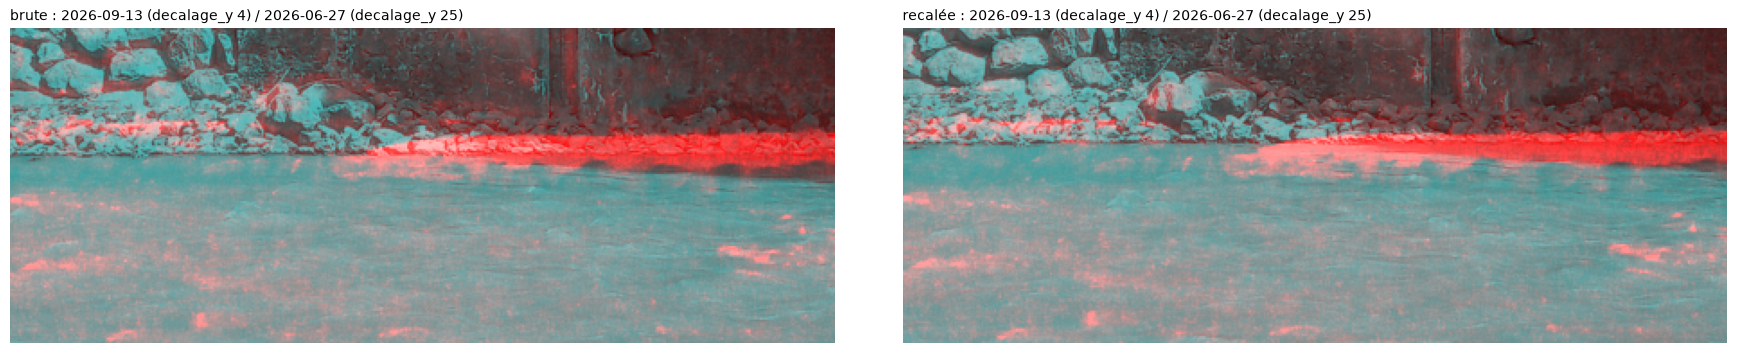

In [12]:
a, b = train.loc[train["decalage_y"].idxmin(), "fichier"], train.loc[train["decalage_y"].idxmax(), "fichier"]
fig, axes = plt.subplots(1, 2, figsize=(18, 3.5))
for ax, recaler in zip(axes, [False, True]):
    va, vb = (pour_afficher(vecteur_bande(f, recaler).reshape((Y1 - Y0) // ECHELLE, -1)) for f in (a, b))
    ax.imshow(np.dstack([va, vb, vb]))
    ax.set_title(f"{'recalée' if recaler else 'brute'} : {a[:10]} (decalage_y {decalages.at[a, 'decalage_y']:.0f}) "
                 f"/ {b[:10]} (decalage_y {decalages.at[b, 'decalage_y']:.0f})", fontsize=10, loc="left")
    ax.axis("off")
plt.tight_layout()

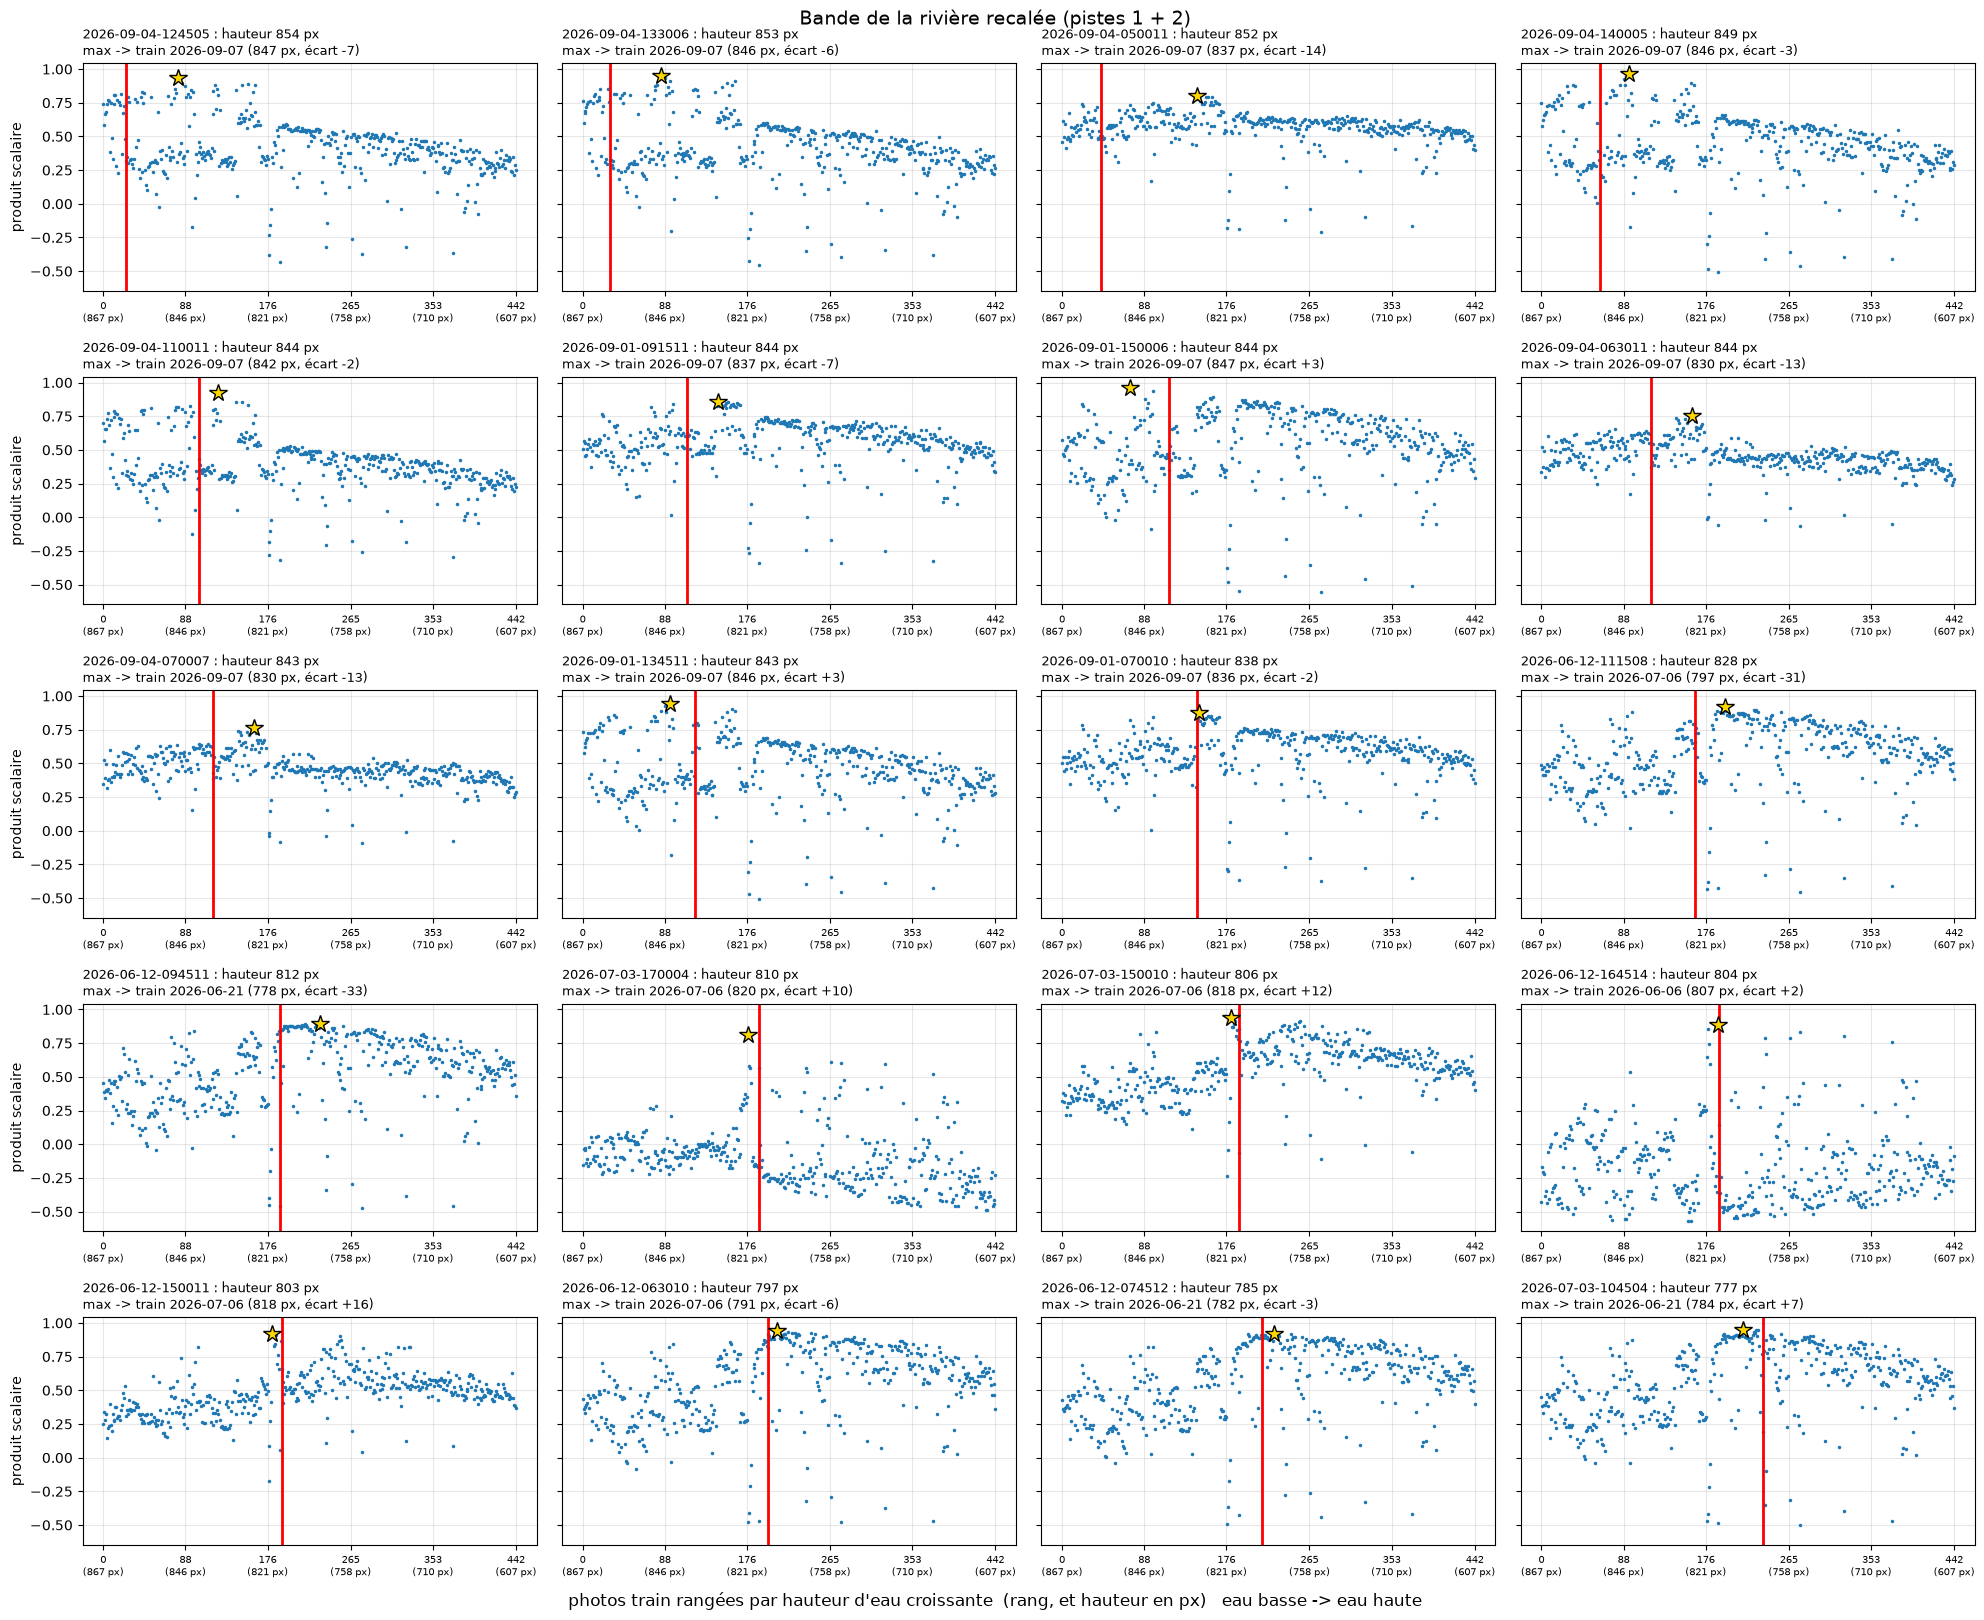

In [13]:
def tracer(M, titre):
    """Un graphique par photo test : produit scalaire avec chaque photo train (rangées par hauteur d'eau croissante)."""
    fig, axes = plt.subplots(int(np.ceil(N_TEST / ncol)), ncol, figsize=(20, 3.3 * np.ceil(N_TEST / ncol)), sharey=True)
    for i, (ax, t) in enumerate(zip(axes.ravel(), test.itertuples())):
        ax.plot(rang, M[i], ".", ms=3)
        ax.axvline(np.searchsorted(-h_train, -t.hauteur_px), color="red", lw=2)
        j = int(np.argmax(M[i]))
        ax.plot(j, M[i, j], "*", color="gold", mec="k", ms=13)
        ax.set_title(f"{t.fichier[:-4]} : hauteur {t.hauteur_px:.0f} px\n"
                     f"max -> train {train.at[j, 'fichier'][:10]} ({h_train[j]:.0f} px, écart {h_train[j] - t.hauteur_px:+.0f})",
                     fontsize=9, loc="left")
        ax.set_xticks(graduations, etiquettes, fontsize=7)
        ax.grid(alpha=.3)
    for ax in axes.ravel()[N_TEST:]:
        ax.axis("off")
    for ax in axes[:, 0]:
        ax.set_ylabel("produit scalaire")
    fig.suptitle(titre, fontsize=14)
    fig.supxlabel("photos train rangées par hauteur d'eau croissante  (rang, et hauteur en px)   eau basse -> eau haute")
    plt.tight_layout()


tracer(PS_variantes["bande recalée"], "Bande de la rivière recalée (pistes 1 + 2)")

In [14]:
# Comparaison des trois variantes : hauteur de la photo train la plus ressemblante vs vraie hauteur
vraie = test["hauteur_px"].to_numpy()
# écart en jours entre chaque photo test et chaque photo train
d_te, d_tr = (pd.to_datetime(df["fichier"].str[:10]).to_numpy() for df in (test, train))
jours = np.abs((d_te[:, None] - d_tr[None, :]) / np.timedelta64(1, "D"))
lignes = []
for nom_var, M in PS_variantes.items():
    j = M.argmax(axis=1)
    e = np.abs(h_train[j] - vraie)
    lignes.append({"variante": nom_var, "|écart| médian (px)": np.median(e), "|écart| max (px)": e.max(),
                   "à 10 px près": f"{(e <= 10).sum()}/{N_TEST}",
                   "max à 7 jours ou moins": f"{(jours[np.arange(N_TEST), j] <= 7).sum()}/{N_TEST}"})
resume = pd.DataFrame(lignes).set_index("variante").round(1)

# détail par photo test
detail = test[["fichier", "hauteur_px"]].copy()
for nom_var, M in PS_variantes.items():
    detail[f"écart {nom_var}"] = (h_train[M.argmax(axis=1)] - vraie).round(0)
display(resume)
detail

,|écart| médian (px),|écart| max (px),à 10 px près,max à 7 jours ou moins
variante,,,,
image entière,11.6,143.4,8/20,16/20
bande,6.4,37.5,12/20,15/20
bande recalée,7.1,33.4,12/20,14/20


,fichier,hauteur_px,écart image entière,écart bande,écart bande recalée
0,2026-09-04-124505.jpg,853.7,-7.0,-7.0,-7.0
1,2026-09-04-133006.jpg,852.7,-6.0,-6.0,-6.0
2,2026-09-04-050011.jpg,851.5,-18.0,-19.0,-14.0
3,2026-09-04-140005.jpg,849.1,-3.0,-3.0,-3.0
4,2026-09-04-110011.jpg,844.5,-2.0,-2.0,-2.0
5,2026-09-01-091511.jpg,844.0,-11.0,-11.0,-7.0
6,2026-09-01-150006.jpg,843.9,3.0,3.0,3.0
7,2026-09-04-063011.jpg,843.5,-143.0,5.0,-13.0
8,2026-09-04-070007.jpg,843.2,-143.0,1.0,-13.0
9,2026-09-01-134511.jpg,842.7,3.0,3.0,3.0
